# BANK CUSTOMER CHURN PREDICTION ANALYSIS

## 3. DATA PREPARATION

In [2]:
import pandas as pd
import numpy as np

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier


import shap

d:\Đầu ra\BANK CUSTOMER CHURN\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Reading csv files
df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

# Checking info
df_train.info()
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               15000 non-null  int64  
 1   CustomerId       15000 non-null  float64
 2   Surname          15000 non-null  str    
 3   CreditScore      15000 non-null  float64
 4   Geography        15000 non-null  str    
 5   Gender           15000 non-null  str    
 6   Age              15000 non-null  float64
 7   Tenure           15000 non-null  float64
 8   Balance          15000 non-null  float64
 9   NumOfProducts    15000 non-null  float64
 10  HasCrCard        15000 non-null  float64
 11  IsActiveMember   15000 non-null  float64
 12  EstimatedSalary  15000 non-null  float64
 13  Exited           15000 non-null  float64
dtypes: float64(10), int64(1), str(3)
memory usage: 1.6 MB
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Colum

In [4]:
train_ids = df_train["id"]
test_ids = df_test["id"]
print(train_ids, test_ids)

0            0
1            1
2            2
3            3
4            4
         ...  
14995    14995
14996    14996
14997    14997
14998    14998
14999    14999
Name: id, Length: 15000, dtype: int64 0       15000
1       15001
2       15002
3       15003
4       15004
        ...  
9995    24995
9996    24996
9997    24997
9998    24998
9999    24999
Name: id, Length: 10000, dtype: int64


In [5]:
# Drop non-predictive columns that can cause noise and overfitting
cols_to_drop = ["id", "CustomerId", "Surname" ]
df_train = df_train.drop(columns = cols_to_drop, errors = "ignore")
df_test = df_test.drop(columns = cols_to_drop, errors = "ignore")
print("Successfully removed non-predictive columns!")

Successfully removed non-predictive columns!


In [6]:
print("---Training Data---")
df_train.head(5)

---Training Data---


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,675.0,France,Female,37.0,5.0,0.00,1.0,1.0,0.0,131778.57,1.0
1,599.0,France,Male,28.0,8.0,0.00,1.0,1.0,0.0,81299.09,0.0
2,706.0,Germany,Female,40.0,9.0,155619.58,1.0,1.0,1.0,81622.08,1.0
3,705.0,Germany,Male,42.0,3.0,81231.85,2.0,1.0,0.0,134720.51,0.0
4,597.0,France,Male,49.0,9.0,0.00,1.0,1.0,0.0,151844.81,1.0


In [7]:
print("---Testing Data---")
df_test.head(5)

---Testing Data---


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,649.0,Germany,Male,37.0,3.0,106534.40,1.0,1.0,1.0,131173.90
1,717.0,France,Female,41.0,2.0,0.00,2.0,1.0,1.0,93767.03
2,850.0,France,Male,45.0,4.0,0.00,1.0,1.0,0.0,132424.69
3,593.0,France,Male,43.0,8.0,0.00,2.0,1.0,0.0,43921.22
4,682.0,Germany,Female,35.0,3.0,118097.87,2.0,0.0,0.0,123982.14


### Convert Datatypes

In [8]:
# Convert to integer columns for both training and testing sets
int_columns = ["CreditScore", "Age", "Tenure", "NumOfProducts", "HasCrCard", "IsActiveMember"]
for col in int_columns:
    df_train[col] = df_train[col].astype('int64')
    df_test[col] = df_test[col].astype('int64')

# Convert the target variable (Exited) to integer column for training set
df_train["Exited"] = df_train["Exited"].astype('int64')

# Convert to string columns for both training and testing sets
str_columns = ["Geography", "Gender"]
for col in str_columns:
    df_train[col] = df_train[col].astype('object')
    df_test[col] = df_test[col].astype('object')

print("Successfully converted datatypes!")
print("\n ---Update Training Data Summary---")
df_train.info()

Successfully converted datatypes!

 ---Update Training Data Summary---
<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      15000 non-null  int64  
 1   Geography        15000 non-null  object 
 2   Gender           15000 non-null  object 
 3   Age              15000 non-null  int64  
 4   Tenure           15000 non-null  int64  
 5   Balance          15000 non-null  float64
 6   NumOfProducts    15000 non-null  int64  
 7   HasCrCard        15000 non-null  int64  
 8   IsActiveMember   15000 non-null  int64  
 9   EstimatedSalary  15000 non-null  float64
 10  Exited           15000 non-null  int64  
dtypes: float64(2), int64(7), object(2)
memory usage: 1.3+ MB


### Data encoding & scaling

In [9]:
# Separate features (x) and target variable (y) from the training set
X_train = df_train.drop(columns = ["Exited"])
y_train = df_train["Exited"]
X_test = df_test.copy()

categorical_cols = ["Geography", "Gender"]
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output = False)

encoded_train_array = encoder.fit_transform(X_train[categorical_cols])
encoded_test_array = encoder.transform(X_test[categorical_cols])

encoded_train_df = pd.DataFrame(encoded_train_array, columns = encoder.get_feature_names_out(categorical_cols))
encoded_test_df = pd.DataFrame(encoded_test_array, columns = encoder.get_feature_names_out(categorical_cols))

numerical_cols = [col for col in X_train.columns if col not in categorical_cols]
scaler = StandardScaler()

scaled_train_array = scaler.fit_transform(X_train[numerical_cols])
scaled_test_array = scaler.transform(X_test[numerical_cols])

# Convert scaled arrays back to DataFrames with proper column names
scaled_train_df = pd.DataFrame(scaled_train_array, columns=numerical_cols)
scaled_test_df = pd.DataFrame(scaled_test_array, columns=numerical_cols)

# 4.4 Align and concatenate the processed features
# Resetting index to prevent misalignment during concatenation
X_train_processed = pd.concat([scaled_train_df.reset_index(drop=True), encoded_train_df.reset_index(drop=True)], axis=1)
X_test_processed = pd.concat([scaled_test_df.reset_index(drop=True), encoded_test_df.reset_index(drop=True)], axis=1)

print("Data preprocessing, encoding, and scaling completed successfully!")
print(f"Processed Training Features Shape: {X_train_processed.shape}")
print(f"Processed Testing Features Shape: {X_test_processed.shape}")


Data preprocessing, encoding, and scaling completed successfully!
Processed Training Features Shape: (15000, 13)
Processed Testing Features Shape: (10000, 13)


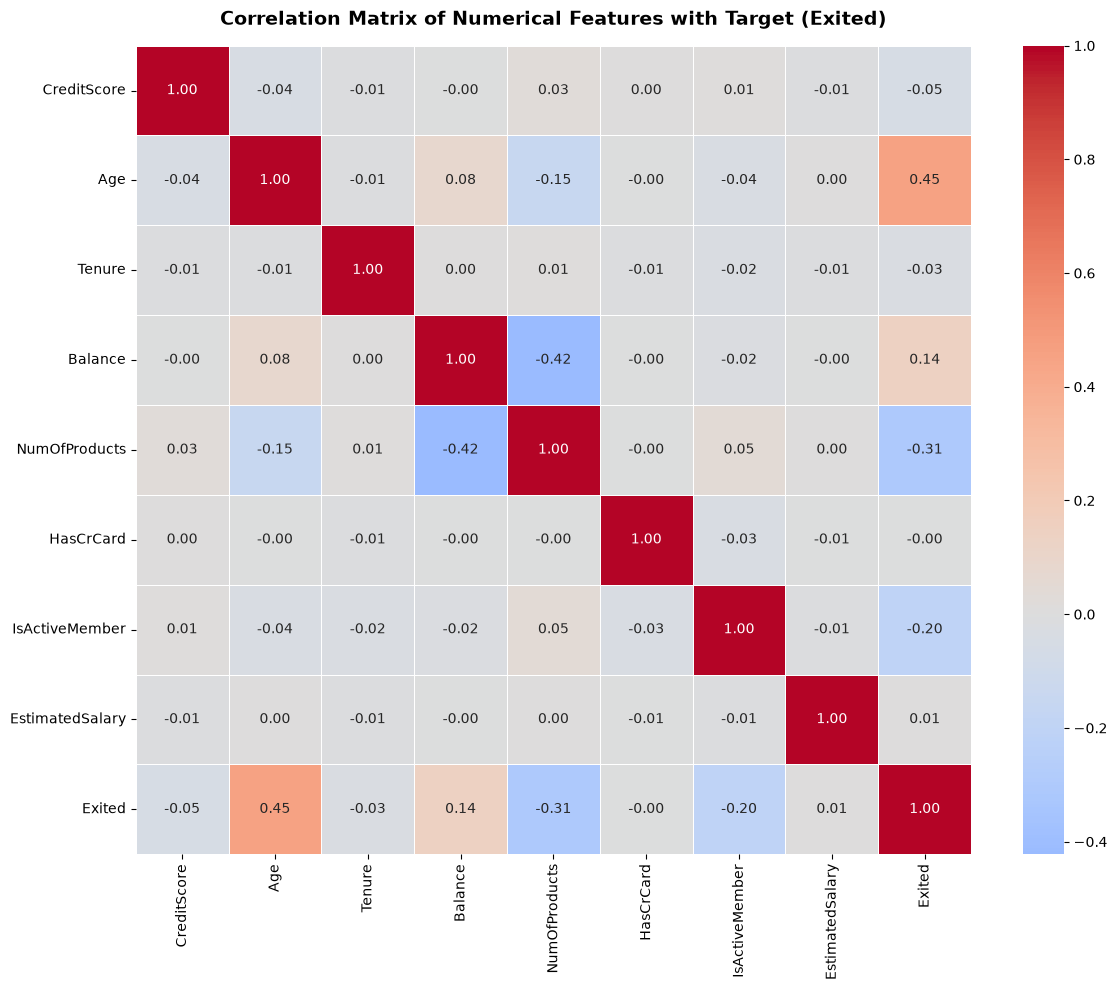

In [10]:
# =====================================================================
# ADD-ON 1: CORRELATION MATRIX HIGH-RESOLUTION VISUALIZATION
# =====================================================================
# Gộp các thuộc tính số và biến mục tiêu Exited để tính độ tương quan
train_numerical_with_target = pd.concat([scaled_train_df, y_train.reset_index(drop=True)], axis=1)

plt.figure(figsize=(12, 10))
# Sử dụng bảng màu 'RdBu_r' hoặc 'coolwarm' để thấy rõ tương quan âm/dương
sns.heatmap(train_numerical_with_target.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Matrix of Numerical Features with Target (Exited)", fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


### TRAIN-VALIDATION SPLIT

In [11]:
# Split the processed training data into 80% training and 20% validation sets
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_processed, 
    y_train, 
    test_size=0.2, 
    random_state=42, 
    stratify=y_train
)

print("Train-Validation split completed successfully!")


Train-Validation split completed successfully!


### MODEL TRAINING AND EVALUATION

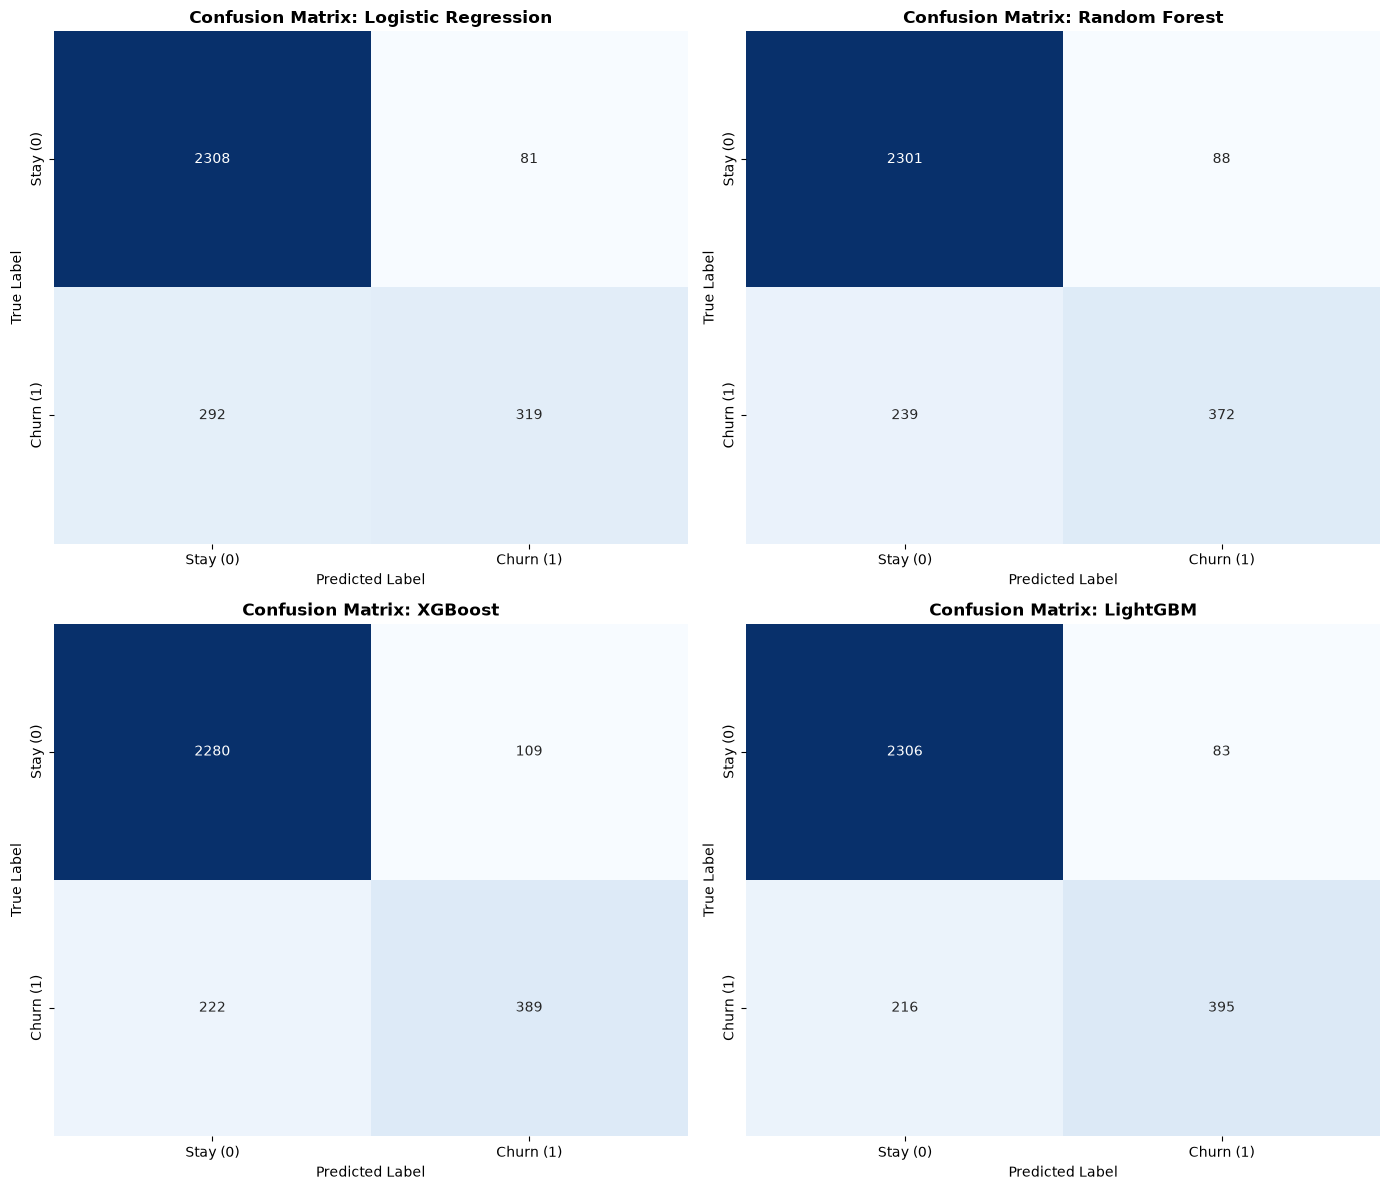


============================== MODEL METRICS COMPARISON TABLE ==============================
                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.8757     0.7975  0.5221    0.6311   0.8862
Random Forest          0.8910     0.8087  0.6088    0.6947   0.9244
XGBoost                0.8897     0.7811  0.6367    0.7015   0.9227
LightGBM               0.9003     0.8264  0.6465    0.7254   0.9325

 Selected Best Model: LightGBM with ROC-AUC = 0.9325


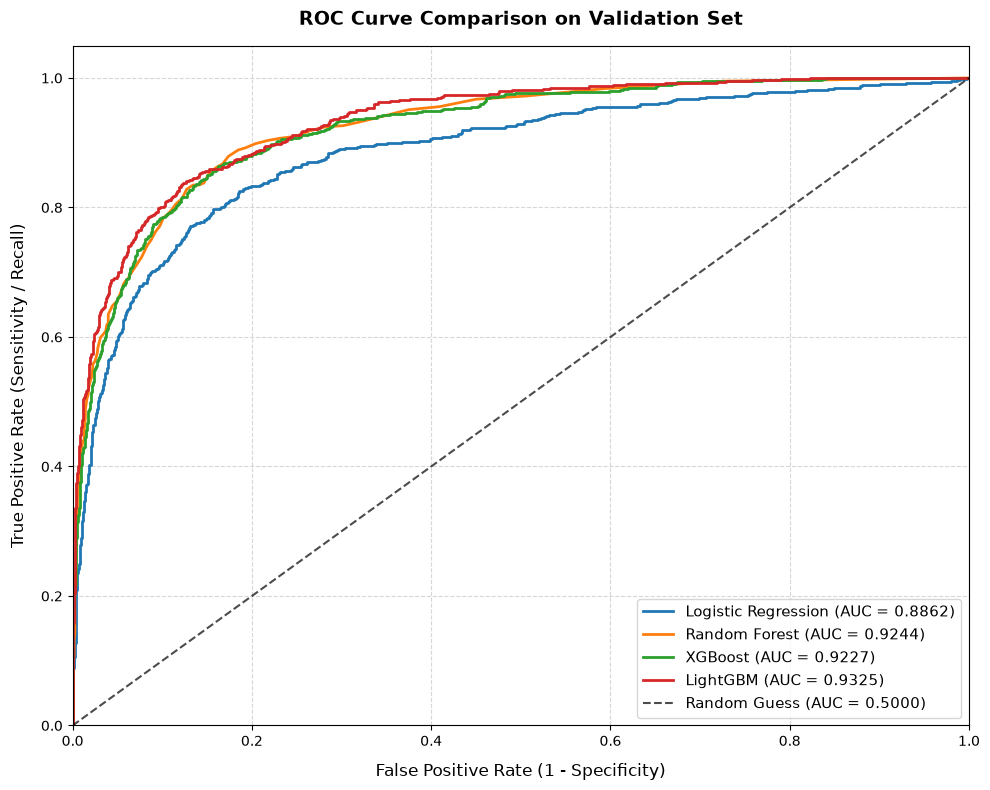

In [12]:
# =====================================================================
# STEP 6: MODEL TRAINING, EVALUATION METRICS & VISUALIZATION
# =====================================================================

# Initialize the machine learning models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss', n_jobs=-1),
    "LightGBM": LGBMClassifier(n_estimators=100, random_state=42, verbose=-1, n_jobs=-1)
}

# Dictionary to store performance metrics for the comparison table
metrics_summary = {}

# Set up the plotting grid for Confusion Matrices (2 rows, 2 columns)
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 12))
axes = axes.flatten()

best_roc_auc = 0
best_model_name = ""
best_model_obj = None

# Loop through each model to train, evaluate, and visualize
for idx, (name, model) in enumerate(models.items()):
    # Train the model
    model.fit(X_tr, y_tr)
    
    # Predict binary classes (0 or 1) and probabilities for the validation set
    y_pred = model.predict(X_val)
    y_pred_proba = model.predict_proba(X_val)[:, 1]
    
    # Calculate all requested metrics
    acc = accuracy_score(y_val, y_pred)
    prec = precision_score(y_val, y_pred)
    rec = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)
    roc_auc = roc_auc_score(y_val, y_pred_proba)
    cm = confusion_matrix(y_val, y_pred)
    
    # Store metrics in the dictionary
    metrics_summary[name] = {
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    }
    
    # Track the best model based on ROC-AUC score
    if roc_auc > best_roc_auc:
        best_roc_auc = roc_auc
        best_model_name = name
        best_model_obj = model
        
    # Visualizing the Confusion Matrix using Seaborn Heatmap
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False,
                xticklabels=['Stay (0)', 'Churn (1)'], yticklabels=['Stay (0)', 'Churn (1)'])
    axes[idx].set_title(f"Confusion Matrix: {name}", fontsize=12, fontweight='bold')
    axes[idx].set_xlabel("Predicted Label")
    axes[idx].set_ylabel("True Label")

# Adjust layout and display the confusion matrix plots
plt.tight_layout()
plt.show()

# Create and display the comprehensive metrics evaluation table
df_metrics = pd.DataFrame(metrics_summary).T
print("\n" + "="*30 + " MODEL METRICS COMPARISON TABLE " + "="*30)
print(df_metrics.round(4)) # Display rounded to 4 decimal places
print("="*92)
print(f"\n Selected Best Model: {best_model_name} with ROC-AUC = {best_roc_auc:.4f}")

# =====================================================================
# ADD-ON 2: ROC CURVE PLOTTING FOR ALL MODELS
# =====================================================================
from sklearn.metrics import roc_curve

plt.figure(figsize=(10, 8))

# Vẽ đường cong ROC cho từng mô hình dựa trên xác suất đã dự đoán ở Step 6
for name, model in models.items():
    y_pred_proba = model.predict_proba(X_val)[:, 1]
    # Tính tỷ lệ Dương tính giả (fpr) và Dương tính thật (tpr)
    fpr, tpr, _ = roc_curve(y_val, y_pred_proba)
    
    # Lấy lại điểm auc để ghi vào chú thích (label)
    auc_score = df_metrics.loc[name, "ROC-AUC"]
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.4f})", linewidth=2)

# Vẽ đường tham chiếu ngẫu nhiên (Random Guess Line - Baseline)
plt.plot([0, 1], [0, 1], 'k--', label="Random Guess (AUC = 0.5000)", alpha=0.7)

# Cấu hình thẩm mỹ cho biểu đồ
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=12, labelpad=10)
plt.ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=12, labelpad=10)
plt.title("ROC Curve Comparison on Validation Set", fontsize=14, fontweight='bold', pad=15)
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [13]:
# =====================================================================
# THRESHOLD TUNING TO BOOST RECALL (RUN ON VALIDATION SET)
# =====================================================================
from sklearn.metrics import precision_recall_curve

# 1. Lấy xác suất dự đoán trên tập Validation của LightGBM
y_val_proba = best_model_obj.predict_proba(X_val)[:, 1]

# 2. Tính toán Precision và Recall cho tất cả các ngưỡng cắt có thể có
precisions, recalls, thresholds = precision_recall_curve(y_val, y_val_proba)

# 3. Tìm ngưỡng cắt (Threshold) giúp F1-Score đạt giá trị cao nhất
f1_scores = 2 * (precisions * recalls) / (precisions + recalls)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f"Ngưỡng cắt mặc định: 0.5000 | Recall: 0.6465")
print(f"Ngưỡng cắt tối ưu nhất (theo F1): {best_threshold:.4f}")

# 4. Áp dụng thử ngưỡng cắt mới (Ví dụ: Giả sử chọn ngưỡng 0.35 để ưu tiên Recall)
custom_threshold = 0.3161 # Bạn có thể điều chỉnh con số này
y_pred_custom = (y_val_proba >= custom_threshold).astype(int)

# 5. In lại ma trận số liệu mới để đối chiếu
print("\n" + "="*20 + f" METRICS AT THRESHOLD = {custom_threshold} " + "="*20)
print(f"New Accuracy : {accuracy_score(y_val, y_pred_custom):.4f}")
print(f"New Precision: {precision_score(y_val, y_pred_custom):.4f}")
print(f"New Recall   : {recall_score(y_val, y_pred_custom):.4f}")
print(f"New F1-Score : {f1_score(y_val, y_pred_custom):.4f}")


Ngưỡng cắt mặc định: 0.5000 | Recall: 0.6465
Ngưỡng cắt tối ưu nhất (theo F1): 0.3161

==================== METRICS AT THRESHOLD = 0.3161 ====================
New Accuracy : 0.8947
New Precision: 0.7323
New Recall   : 0.7610
New F1-Score : 0.7464


### INFERENCE AND SUBMISSION FILE GENERATION

In [17]:
# =====================================================================
# STEP 7: INFERENCE AND SUBMISSION FILE GENERATION
# =====================================================================

# Predict final churn probabilities for the unlabelled test dataset
final_test_predictions = best_model_obj.predict_proba(X_test_processed)[:, 1]

# Construct the output submission dataframe
submission_df = pd.DataFrame({
    "id": test_ids,
    "Churn_Probability": final_test_predictions
})

# Save output to a CSV file
submission_file_name = "bank_churn_predictions.csv"
submission_df.to_csv(submission_file_name, index=False)

print(f"Process finalized! Submission file '{submission_file_name}' generated successfully.")
print("\n--- First 5 rows of the prediction output ---")
print(submission_df.head())

Process finalized! Submission file 'bank_churn_predictions.csv' generated successfully.

--- First 5 rows of the prediction output ---
      id  Churn_Probability
0  15000           0.283286
1  15001           0.025903
2  15002           0.864499
3  15003           0.036437
4  15004           0.030458


### STEP 8: MODEL EXPLAINABILITY VIA SHAP

Calculating SHAP values for the LightGBM model...


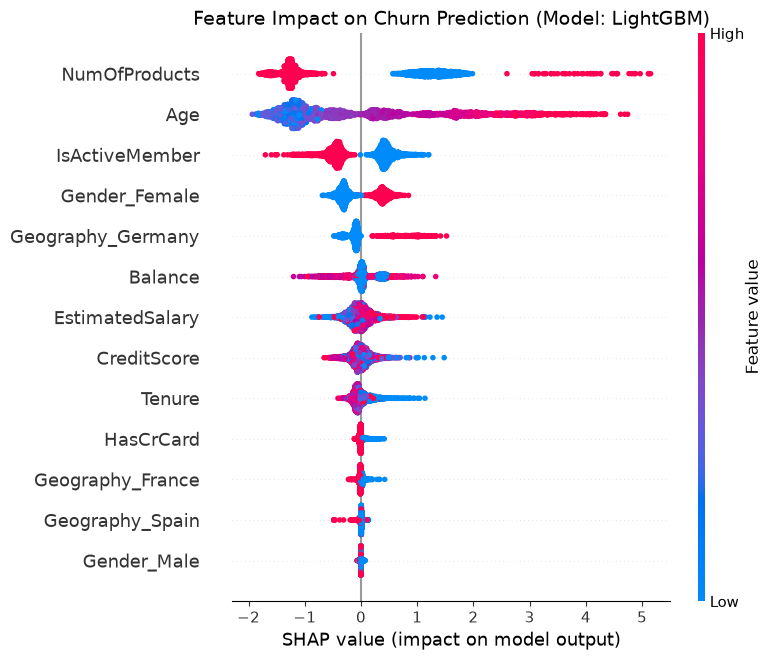

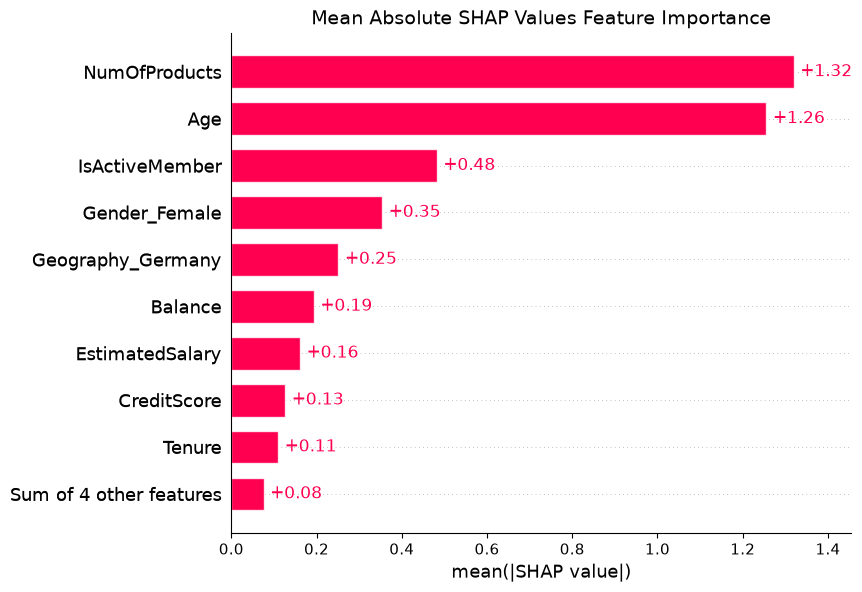

In [ ]:
# =====================================================================
# STEP 8: MODEL EXPLAINABILITY VIA SHAP
# =====================================================================

# Initialize the correct SHAP explainer for the chosen best model
if best_model_name in ["LogisticRegression", "LightGBM", "XGBoost", "Random Forest"]:
    explainer = shap.TreeExplainer(best_model_obj)
else:
    explainer = shap.KernelExplainer(best_model_obj.predict_proba, shap.sample(X_tr, 100))

# Calculate SHAP values on the validation features
print(f"Calculating SHAP values for the {best_model_name} model...")
shap_values = explainer(X_val)

# Plot 1: Summary Feature Importance Plot
plt.figure(figsize=(10, 6))
plt.title(f"Feature Impact on Churn Prediction (Model: {best_model_name})", fontsize=14)
shap.summary_plot(shap_values, X_val)

# Plot 2: Average Absolute SHAP Feature Importance Bar Plot
plt.figure(figsize=(10, 6))
plt.title(f"Mean Absolute SHAP Values Feature Importance", fontsize=14)
shap.plots.bar(shap_values)


In [ ]:
import joblib

# Lưu các đối tượng vào ổ đĩa
joblib.dump(best_model_obj, 'best_lightgbm_model.pkl')
joblib.dump(encoder, 'onehot_encoder.pkl')
joblib.dump(scaler, 'standard_scaler.pkl')
print("Đã lưu mô hình và bộ tiền xử lý thành công!")

Đã lưu mô hình và bộ tiền xử lý thành công!
